# Session 50 Solutions: Capstone Project Plan

Data Science with Python, Level 3, Stage 8: Capstone

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
exams = pd.read_csv(DATA_URL + "exam_scores.csv")

## In-Class Exercises

### In-Class Exercise 1: Three Ideas

In [2]:
ideas = pd.DataFrame([
    {"question": "Which students are likely to fail?", "data": "exam_scores.csv", "target": "passed", "user": "teachers"},
    {"question": "What is a fair price for this flat?", "data": "apartments.csv", "target": "price_k", "user": "buyers"},
    {"question": "How many bikes will be rented tomorrow?", "data": "bike_rentals.csv", "target": "rentals", "user": "operations team"},
])
ideas

,question,data,target,user
0,Which students are likely to fail?,exam_scores.csv,passed,teachers
1,What is a fair price for this flat?,apartments.csv,price_k,buyers
2,How many bikes will be rented tomorrow?,bike_rentals.csv,rentals,operations team


### In-Class Exercise 2: Score the Ideas

In [3]:
scores = pd.DataFrame({
    "idea": ["students", "flats", "bikes"],
    "useful": [5, 4, 4], "data": [4, 4, 5], "doable": [5, 5, 4],
})
scores["total"] = scores[["useful", "data", "doable"]].sum(axis=1)
scores.sort_values("total", ascending=False)

,idea,useful,data,doable,total
0,students,5,4,5,14
1,flats,4,4,5,13
2,bikes,4,5,4,13


### In-Class Exercise 3: Profile Your Data

In [4]:
def quick_profile(df):
    profile = pd.DataFrame({"type": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique(), "example": df.iloc[0]})
    print(f"{df.shape[0]} rows, {df.shape[1]} columns, {df.duplicated().sum()} duplicate rows")
    return profile

print(quick_profile(exams))
# To check: student_id is an identifier, not a feature; exam marks leak the target; class is text and needs encoding.

500 rows, 9 columns, 0 duplicate rows
                     type  missing  unique example
student_id          int64        0     500       1
class                 str        0       5       C
study_hours_week  float64        0     147    12.7
sleep_hours       float64        0      52     5.5
attendance_pct      int64        0      36      91
math                int64        0      68      62
physics             int64        0      59      57
english             int64        0      42      84
passed               bool        0       2    True


### In-Class Exercise 4: Partner Check

In [5]:
# Partner concerns:
# - Known in time: attendance is only complete at the end of term; use attendance up to week 6 instead.
# - Doable: start with logistic regression; try boosting only if time remains.
print("Plan checked")

Plan checked


## Part A: Basic

### Exercise 1: Milestone 1: The One-Page Plan

In [6]:
plan = '''
Student Success Predictor
Pitch: flags students at risk of failing early in the term, so teachers can offer extra support.
Question: which students are likely to fail the final exams? User: class teachers.
Data: exam_scores.csv, 500 students; target passed; features study hours, sleep, attendance, class.
Metric: recall for failing students (missing one is costly), with ROC AUC; baseline 55 percent accuracy.
Risks: small dataset; attendance may not be complete early in term. Backup: use fewer features.
'''
print(plan)


Student Success Predictor
Pitch: flags students at risk of failing early in the term, so teachers can offer extra support.
Question: which students are likely to fail the final exams? User: class teachers.
Data: exam_scores.csv, 500 students; target passed; features study hours, sleep, attendance, class.
Metric: recall for failing students (missing one is costly), with ROC AUC; baseline 55 percent accuracy.
Risks: small dataset; attendance may not be complete early in term. Backup: use fewer features.



### Exercise 2: Milestone 2: Load and Profile

In [7]:
def quick_profile(df):
    profile = pd.DataFrame({"type": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique(), "example": df.iloc[0]})
    print(f"{df.shape[0]} rows, {df.shape[1]} columns, {df.duplicated().sum()} duplicate rows")
    return profile

print(quick_profile(exams))
print(exams["passed"].value_counts(normalize=True).round(2))
exclude = {"identifier": ["student_id"], "leaky": ["math", "physics", "english"]}
print(exclude)

500 rows, 9 columns, 0 duplicate rows
                     type  missing  unique example
student_id          int64        0     500       1
class                 str        0       5       C
study_hours_week  float64        0     147    12.7
sleep_hours       float64        0      52     5.5
attendance_pct      int64        0      36      91
math                int64        0      68      62
physics             int64        0      59      57
english             int64        0      42      84
passed               bool        0       2    True
passed
False    0.55
True     0.45
Name: proportion, dtype: float64
{'identifier': ['student_id'], 'leaky': ['math', 'physics', 'english']}


## Part B: Intermediate

### Exercise 3: Milestone 3: Baseline

A dummy model always has a ROC AUC of 0.5, because it gives every row the same score.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
features = ["class", "study_hours_week", "sleep_hours", "attendance_pct"]
X_dev, X_test, y_dev, y_test = train_test_split(exams[features], exams["passed"], test_size=0.2, stratify=exams["passed"], random_state=0)
pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["class"]), ("num", StandardScaler(), features[1:])])
for name, model in [("dummy", DummyClassifier(strategy="most_frequent")), ("logistic", make_pipeline(pre, LogisticRegression()))]:
    print(name, cross_val_score(model, X_dev, y_dev, cv=5, scoring="roc_auc").mean().round(3))

dummy 0.5
logistic 0.716


### Exercise 4: Milestone 4: First Charts

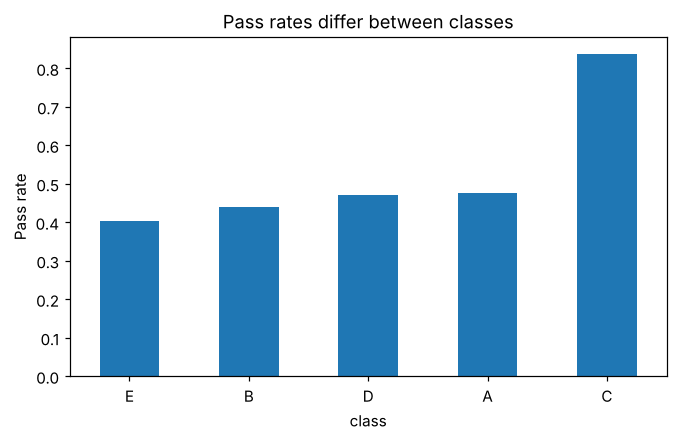

In [9]:
exams["study_group"] = pd.qcut(exams["study_hours_week"], 5)
exams.groupby("study_group", observed=True)["passed"].mean().plot(kind="bar", rot=20)
plt.title("Pass rate rises steadily with weekly study hours")
plt.ylabel("Pass rate")
plt.show()
exams.groupby("class")["passed"].mean().sort_values().plot(kind="bar", rot=0)
plt.title("Pass rates differ between classes")
plt.ylabel("Pass rate")
plt.show()

## Part C: Challenge

### Exercise 5: Milestone 5: Repository Skeleton

In [10]:
# GitHub: New repository, e.g. student-success-predictor, Public, Add a README.
# Upload .gitignore and requirements.txt (generated as in Sessions 46 and 49).
# Colab: File, Save a copy in GitHub, path notebooks/01_plan_and_baseline.ipynb.
print("https://github.com/YOUR_USERNAME/student-success-predictor")

https://github.com/YOUR_USERNAME/student-success-predictor


## Part D: Cumulative Project

### Exercise 6: Milestone 6: Risks and Backup Plan

In [11]:
risks = pd.DataFrame([
    {"risk": "Model barely beats the baseline", "likelihood": "medium", "impact": "high", "backup": "Engineer features; present an honest analysis of why"},
    {"risk": "Deployment errors", "likelihood": "medium", "impact": "high", "backup": "Deploy version 1 early; pin versions"},
    {"risk": "Not enough time", "likelihood": "high", "impact": "medium", "backup": "Finish the minimum viable project first"},
])
order = {"high": 0, "medium": 1, "low": 2}
risks.sort_values("likelihood", key=lambda s: s.map(order))

,risk,likelihood,impact,backup
2,Not enough time,high,medium,Finish the minimum viable project first
0,Model barely beats the baseline,medium,high,Engineer features; present an honest analysis ...
1,Deployment errors,medium,high,Deploy version 1 early; pin versions


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | It names a target, a time frame and a decision. |
| 2 | B | That is leakage. |
| 3 | B | Every real model must beat it. |
| 4 | A | Finish it first, then improve. |
| 5 | B | Early deployment reveals problems while there is time. |